<a href="https://colab.research.google.com/github/malachifletcher/bafad-research-track/blob/main/task-b/task_b_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task B — From R to Python: Translating Statistical Analysis
> **BAFAD Accelerated Research Track · Fall 2026**

This task bridges your STAT 270 R work with the Python data science ecosystem used in AI research.
You will reproduce three analyses from Assignment 1 — originally written in R using `dplyr` and `ggplot2` — in Python using `pandas` and `matplotlib`.

**Reference file:** `task_b_r_original.R` (in this folder) — contains the complete R code you are translating.

**Data:** `../data/flights.csv` and `../data/airports.csv`

**Submission:** Push your completed notebook to your fork of the starter repository and paste the repo URL into the Canvas assignment.

## Setup

Run this cell first.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

NAVY = '#021B3A'
BLUE = '#0EA5E9'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

flights  = pd.read_csv('/content/flights.csv')
airports = pd.read_csv('/content/airports.csv')

print(f'flights:  {flights.shape[0]:,} rows × {flights.shape[1]} columns')
print(f'airports: {airports.shape[0]} rows × {airports.shape[1]} columns')
flights.head(3)

flights:  1,000 rows × 19 columns
airports: 35 rows × 8 columns


,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,7,27,669,645,24,1083,1059,45,F9,4502,N772AA,LGA,MKE,254,2294,6,45,2013-07-27 06:00:00
1,2013,7,11,693,715,-22,1334,1356,-9,YV,8275,N414EF,LGA,MCO,401,3254,7,15,2013-07-11 07:00:00
2,2013,3,3,1466,1415,51,2071,2020,58,F9,6396,N348AE,JFK,PHX,365,3196,14,15,2013-03-03 14:00:00


---
## Question 2 — Frequency Tables and Proportions (10 pts)

### Part A (4 pts)
Compute the **number of flights** and the **proportion of all flights** operated by each carrier.
Display the result sorted from most to least flights.

**R equivalent:**
```r
flights |> count(carrier, sort = TRUE) |> mutate(prop = n / sum(n))
```

*Python hints:*
- `flights['carrier'].value_counts()` gives counts sorted descending.
- Divide by `len(flights)` to get proportions.
- Build a `pd.DataFrame` with columns `carrier`, `n`, `prop`.

In [4]:
carrier_counts = flights['carrier'].value_counts()

carrier_counts = pd.DataFrame({
    'carrier': carrier_counts.index,
    'n': carrier_counts.values,
    'prop': carrier_counts.values / len(flights)
})

carrier_counts

,carrier,n,prop
0,F9,74,0.074
1,B6,72,0.072
2,US,71,0.071
3,UA,68,0.068
4,DL,67,0.067
5,MQ,66,0.066
6,VX,64,0.064
7,9E,63,0.063
8,YV,61,0.061
9,EV,61,0.061


**Answer** — Which carrier operated the most flights? What was its approximate share?

> _Write here._

### Part B (6 pts)
Compute the **proportion of flights that arrived late** (`arr_delay > 0`) for each carrier,
sorted from highest to lowest late-arrival rate.

**R equivalent:**
```r
flights |> group_by(carrier) |>
  summarise(late_rate = mean(arr_delay > 0, na.rm = TRUE)) |>
  arrange(desc(late_rate))
```

*Python hints:*
- `(flights['arr_delay'] > 0)` produces a boolean Series; take `.mean()` per group.
- Use `groupby('carrier').apply(...)` or `groupby('carrier')['arr_delay'].agg(...)`.

In [5]:
late_arrivals = (
    flights.groupby('carrier')['arr_delay']
    .apply(lambda x: (x.dropna() > 0).mean())
    .reset_index(name='late_rate')
    .sort_values('late_rate', ascending=False)
)

late_arrivals

,carrier,late_rate
2,AS,0.735849
11,UA,0.705882
15,YV,0.704918
12,US,0.704225
8,HA,0.689655
13,VX,0.687500
4,DL,0.686567
1,AA,0.672414
0,9E,0.650794
5,EV,0.639344


**Answer** — Which carrier had the worst on-time arrival record?

> _Write here._

---
## Question 3 — Histogram, Density, and Shape (15 pts)

### Part A (7 pts)
Create a **density histogram** of `dep_delay`, restricted to flights where `dep_delay` is between −60 and 180 minutes.
Overlay a kernel density estimate (KDE) curve.

- Use `NAVY` (`'#021B3A'`) for the histogram bars.
- Use `BLUE` (`'#0EA5E9'`) for the KDE line.
- Apply `plt.style.use('seaborn-v0_8-whitegrid')` or `plt.rcParams` for a clean background.

**R equivalent:**
```r
flights_filtered |> ggplot(aes(x = dep_delay)) +
  geom_histogram(aes(y = after_stat(density)), fill='#021B3A') +
  geom_density(colour='#0EA5E9') + theme_bw()
```

*Python hints:*
- Filter: `df_filtered = flights[(flights['dep_delay'] >= -60) & (flights['dep_delay'] <= 180)]`
- `ax.hist(..., density=True)` gives a density-normalised histogram.
- `from scipy.stats import gaussian_kde` or `df_filtered['dep_delay'].plot.kde(ax=ax)` for the curve.

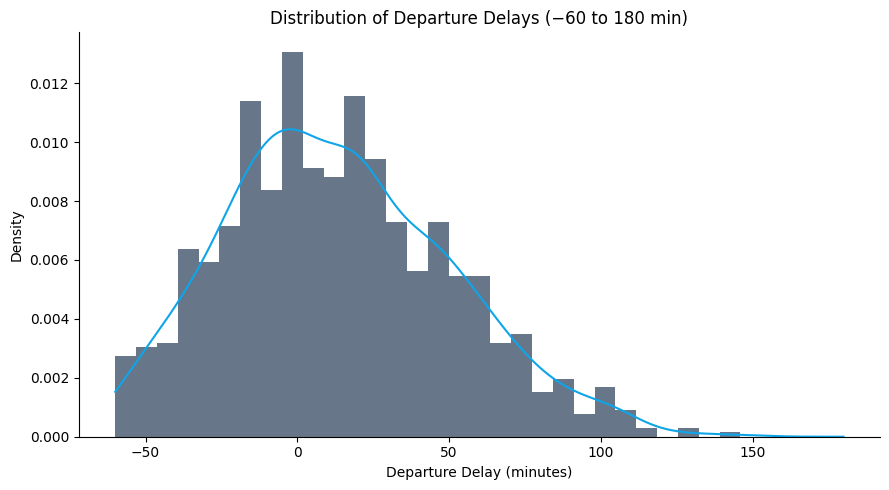

In [8]:
from scipy.stats import gaussian_kde

df_filtered = flights[(flights['dep_delay'] >= -60) & (flights['dep_delay'] <= 180)].copy()

fig, ax = plt.subplots(figsize=(9, 5))

# YOUR CODE HERE — density histogram + KDE
# Density histogram
ax.hist(
    df_filtered['dep_delay'].dropna(),
    bins=30,
    density=True,
    color=NAVY,
    alpha=0.6
)

# KDE curve
delays = df_filtered['dep_delay'].dropna()
kde = gaussian_kde(delays)

x_vals = np.linspace(-60, 180, 300)
ax.plot(x_vals, kde(x_vals), color=BLUE)

ax.set_xlabel('Departure Delay (minutes)')
ax.set_ylabel('Density')
ax.set_title('Distribution of Departure Delays (−60 to 180 min)')
plt.tight_layout()
plt.show()

### Part B (8 pts)
Compute and report the **median** and **IQR** of `dep_delay` (same filtered range), then describe the distribution in complete sentences addressing: shape, modality, centre, and spread.

In [9]:
# YOUR CODE HERE
median_delay = df_filtered['dep_delay'].median()
iqr_delay    = (
    df_filtered['dep_delay'].quantile(0.75)
    - df_filtered['dep_delay'].quantile(0.25)
)
print(f'Median departure delay: {median_delay:.1f} min')
print(f'IQR of departure delay: {iqr_delay:.1f} min')

Median departure delay: 11.0 min
IQR of departure delay: 53.8 min


**Answer** — Shape, modality, centre, spread:

> _Write here._

---
## Question 4 — Grouped Summaries by Origin Airport (15 pts)

### Part A (7 pts)
For each of the three origin airports (EWR, JFK, LGA), compute the **mean, median, standard deviation, and IQR** of `arr_delay`.
Display the results as a summary table.

**R equivalent:**
```r
flights |> group_by(origin) |>
  summarise(mean_arr=mean(arr_delay,na.rm=T), median_arr=median(...), sd_arr=sd(...), iqr_arr=IQR(...))
```

*Python hints:*
- Use `flights.groupby('origin')['arr_delay'].agg(['mean','median','std'])` and add IQR via `lambda`.
- For IQR: `from scipy.stats import iqr` or `lambda x: x.quantile(0.75) - x.quantile(0.25)`.

In [11]:
from scipy.stats import iqr as scipy_iqr

# YOUR CODE HERE
origin_summary = flights.groupby('origin')['arr_delay'].agg(
    mean_arr='mean',
    median_arr='median',
    sd_arr='std',
    iqr_arr=lambda x: x.quantile(0.75) - x.quantile(0.25)
)

origin_summary

,mean_arr,median_arr,sd_arr,iqr_arr
origin,,,,
EWR,16.344411,15.0,43.273994,56.0
JFK,20.057637,19.0,43.273791,58.0
LGA,15.096273,15.0,42.417081,57.5


### Part B (8 pts)
Based on your table, answer in complete sentences:
1. Which airport has the **highest mean** arrival delay? Lowest?
2. For each airport, is the mean **higher or lower** than the median? What does this imply about the shape of each delay distribution?
3. Which airport shows the **greatest spread** (use SD to support your answer)?

**Answer:**

> JFK had the highest mean arrival delay at approximately 20.06 minutes, while LGA had the lowest at approximately 15.10 minutes. The median arrival delays were close to the means for all three airports, suggesting the distributions are relatively balanced, though this alone does not confirm symmetry. EWR had the largest IQR at 56 minutes, while JFK had the largest standard deviation at approximately 43.27 minutes, indicating slightly greater variability in arrival delays.

---
## Reflection (not graded — but read before Task C)

Take 5 minutes to jot down:
- What was the hardest part of translating R to Python?
- What Python feature did you find most useful or surprising?
- How do `pandas` and `dplyr` differ in their approach to grouped operations?

You will expand on this in `task-c/reflection.md`.